# 🏡 California Housing Prices — Training Set Exploratory Data Analysis (EDA)

This notebook performs comprehensive exploratory data analysis and visualization on the **stratified training set** of the California Housing dataset.

### Objectives:
1. **Stratified Sampling**: Ensure representative train/test splits based on median income categories.
2. **Distribution Analysis**: Understand feature distributions, skews, and value boundaries.
3. **Geographical Visualization**: Map housing clusters, population density, and price distributions across California.
4. **Correlation Analysis**: Identify linear and non-linear relationships using correlation heatmaps and scatter matrices.
5. **Categorical Analysis**: Explore the price impact of ocean proximity.
6. **Feature Engineering Insights**: Evaluate the predictive power of synthesized attributes (e.g., rooms per household, bedroom ratios).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set aesthetics and styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

# Load the full dataset
df = pd.read_csv("housing.csv")
print(f"Dataset Shape: {df.shape[0]:,} rows, {df.shape[1]} columns")
df.head()

Dataset Shape: 20,640 rows, 10 columns


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 1. Stratified Train-Test Split

To prevent sampling bias when predicting house prices, we stratify by `median_income` (the most critical numeric predictor). We partition income into five distinct categories matching the production pipeline.

In [2]:
from sklearn.model_selection import StratifiedShuffleSplit

# Discretize median income into 5 categories
df["income_cat"] = pd.cut(
    df["median_income"],
    bins=[0.0, 1.5, 3.0, 4.5, 6.0, np.inf],
    labels=[1, 2, 3, 4, 5]
)

# Perform stratified split (80% train, 20% test)
split = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
for train_index, test_index in split.split(df, df["income_cat"]):
    strat_train_set = df.loc[train_index].copy()
    strat_test_set = df.loc[test_index].copy()

# Verify that category proportions are preserved
prop_full = df["income_cat"].value_counts(normalize=True).sort_index()
prop_train = strat_train_set["income_cat"].value_counts(normalize=True).sort_index()
prop_test = strat_test_set["income_cat"].value_counts(normalize=True).sort_index()

comparison_df = pd.DataFrame({
    "Full Dataset (%)": prop_full * 100,
    "Train Set (%)": prop_train * 100,
    "Test Set (%)": prop_test * 100
})
display(comparison_df.round(2))

# Drop helper column from sets
for s in (strat_train_set, strat_test_set):
    s.drop("income_cat", axis=1, inplace=True)

# Create an exploratory copy of the training set
housing = strat_train_set.copy()
print(f"Exploratory Training Set Shape: {housing.shape}")

,Full Dataset (%),Train Set (%),Test Set (%)
income_cat,,,
1,3.98,3.98,4.00
2,31.88,31.89,31.88
3,35.06,35.06,35.05
4,17.63,17.63,17.64
5,11.44,11.45,11.43


Exploratory Training Set Shape: (16512, 10)


## 2. Feature Distributions & Summary Statistics

Inspecting the distribution of each numerical feature reveals skewness, potential outliers, and artificial caps in the data collection process.

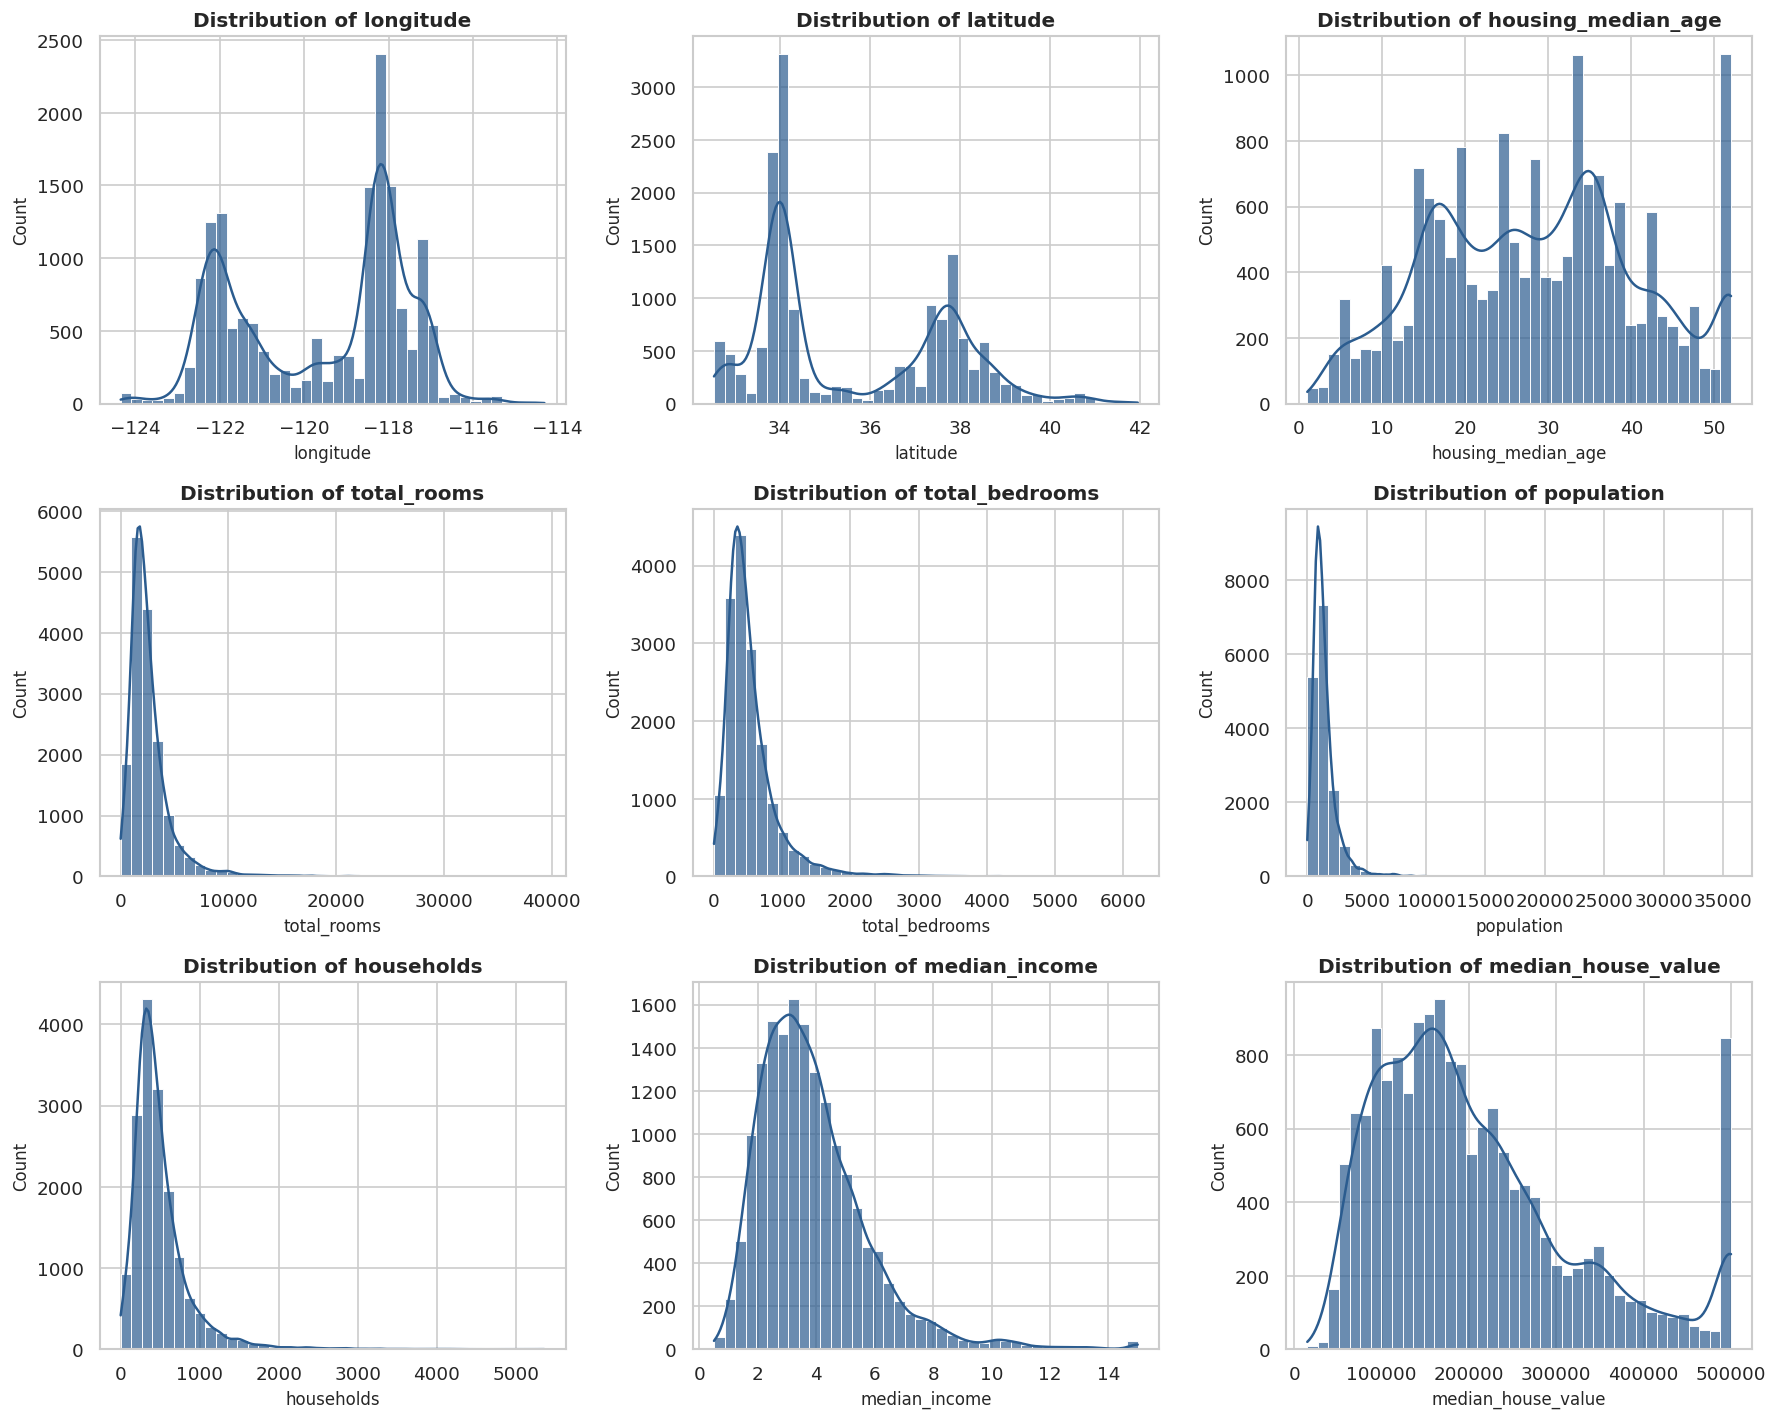

In [3]:
# Overview of numeric distributions
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

num_cols = housing.select_dtypes(include=[np.number]).columns

for i, col in enumerate(num_cols):
    sns.histplot(
        housing[col],
        kde=True,
        ax=axes[i],
        color="#2b5c8f",
        bins=40,
        edgecolor="white",
        alpha=0.7
    )
    axes[i].set_title(f"Distribution of {col}", fontsize=12, fontweight="bold")
    axes[i].set_xlabel(col, fontsize=10)
    axes[i].set_ylabel("Count", fontsize=10)

plt.tight_layout()
plt.show()

> **Key Observations from Distributions:**
> 1. `median_house_value` is capped at $500,000 (evident by the vertical spike at the far right).
> 2. `housing_median_age` is capped at 50 years.
> 3. Features like `total_rooms`, `total_bedrooms`, `population`, and `households` have long right tails (positive skew).
> 4. `median_income` has been preprocessed/scaled (clustered between 2 and 6, representing tens of thousands of USD).

## 3. Geographical Visualizations: California Housing Density & Prices

Visualizing longitude on the horizontal axis and latitude on the vertical axis projects a geographic map of California.

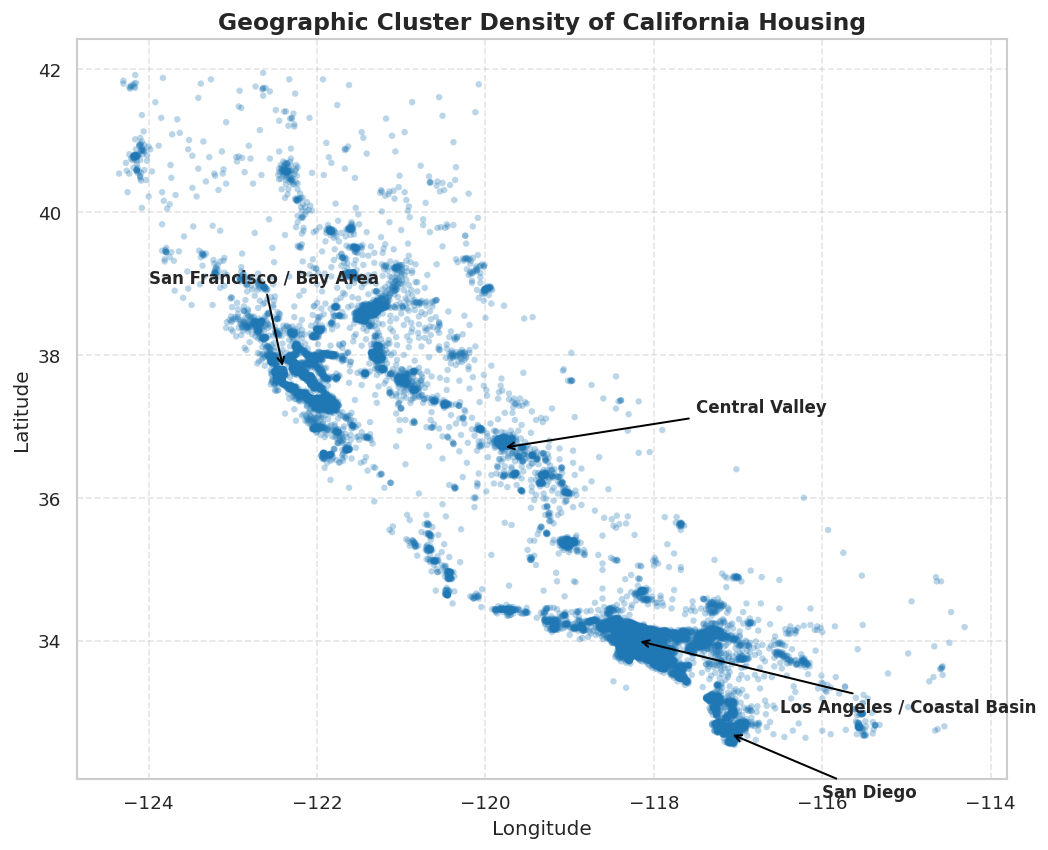

In [4]:
# High-density geographic scatter plot
fig, ax = plt.subplots(figsize=(10, 8))

scatter = ax.scatter(
    housing["longitude"],
    housing["latitude"],
    alpha=0.3,
    c="#1f77b4",
    s=15,
    edgecolors="none"
)
ax.set_title("Geographic Cluster Density of California Housing", fontsize=14, fontweight="bold")
ax.set_xlabel("Longitude", fontsize=12)
ax.set_ylabel("Latitude", fontsize=12)
ax.grid(True, linestyle="--", alpha=0.5)

# Annotate prominent California regions
ax.annotate("San Francisco / Bay Area", xy=(-122.4, 37.8), xytext=(-124.0, 39.0),
            arrowprops=dict(arrowstyle="->", color="black", lw=1.2), fontsize=10, fontweight="bold")
ax.annotate("Los Angeles / Coastal Basin", xy=(-118.2, 34.0), xytext=(-116.5, 33.0),
            arrowprops=dict(arrowstyle="->", color="black", lw=1.2), fontsize=10, fontweight="bold")
ax.annotate("San Diego", xy=(-117.1, 32.7), xytext=(-116.0, 31.8),
            arrowprops=dict(arrowstyle="->", color="black", lw=1.2), fontsize=10, fontweight="bold")
ax.annotate("Central Valley", xy=(-119.8, 36.7), xytext=(-117.5, 37.2),
            arrowprops=dict(arrowstyle="->", color="black", lw=1.2), fontsize=10, fontweight="bold")

plt.show()

Now, let's enrich this geographical map by plotting:
- **Circle size ($s$):** District population (larger circles = higher population).
- **Circle color ($c$):** Median house value using the `turbo` / `jet` colormap.

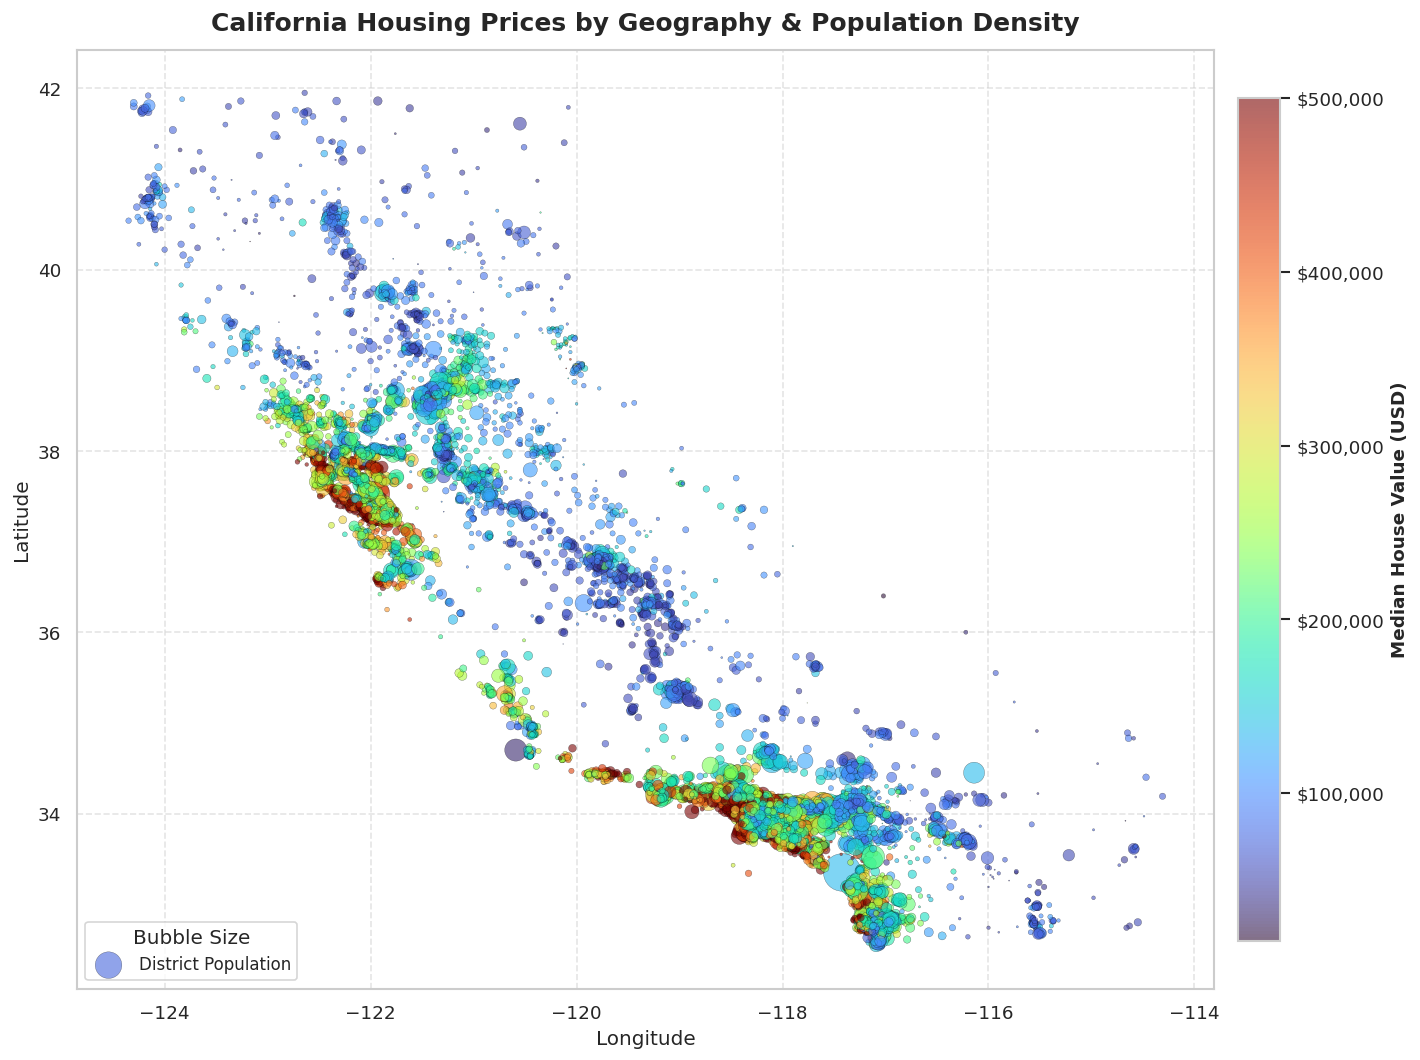

In [5]:
# Comprehensive California Housing & Price Map
fig, ax = plt.subplots(figsize=(12, 9))

map_plot = ax.scatter(
    housing["longitude"],
    housing["latitude"],
    c=housing["median_house_value"],
    s=housing["population"] / 70,
    cmap="turbo",
    alpha=0.6,
    edgecolors="black",
    linewidth=0.2,
    label="District Population"
)

# Colorbar formatting
cbar = plt.colorbar(map_plot, ax=ax, fraction=0.035, pad=0.02)
cbar.set_label("Median House Value (USD)", fontsize=11, fontweight="bold")
cbar.ax.yaxis.set_major_formatter("${x:,.0f}")

ax.set_title("California Housing Prices by Geography & Population Density", fontsize=15, fontweight="bold", pad=12)
ax.set_xlabel("Longitude", fontsize=12)
ax.set_ylabel("Latitude", fontsize=12)
ax.legend(title="Bubble Size", loc="lower left", frameon=True, fontsize=10)
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

> **Geographical Insights:**
> - Prices are very strongly tied to location: proximity to the coast and major urban centers (San Francisco Bay Area and Los Angeles/San Diego) drives the highest prices.
> - Inland/Central Valley areas are significantly more affordable despite substantial population clusters.

## 4. Impact of Ocean Proximity on House Values

Let's examine how the categorical feature `ocean_proximity` relates to house values.

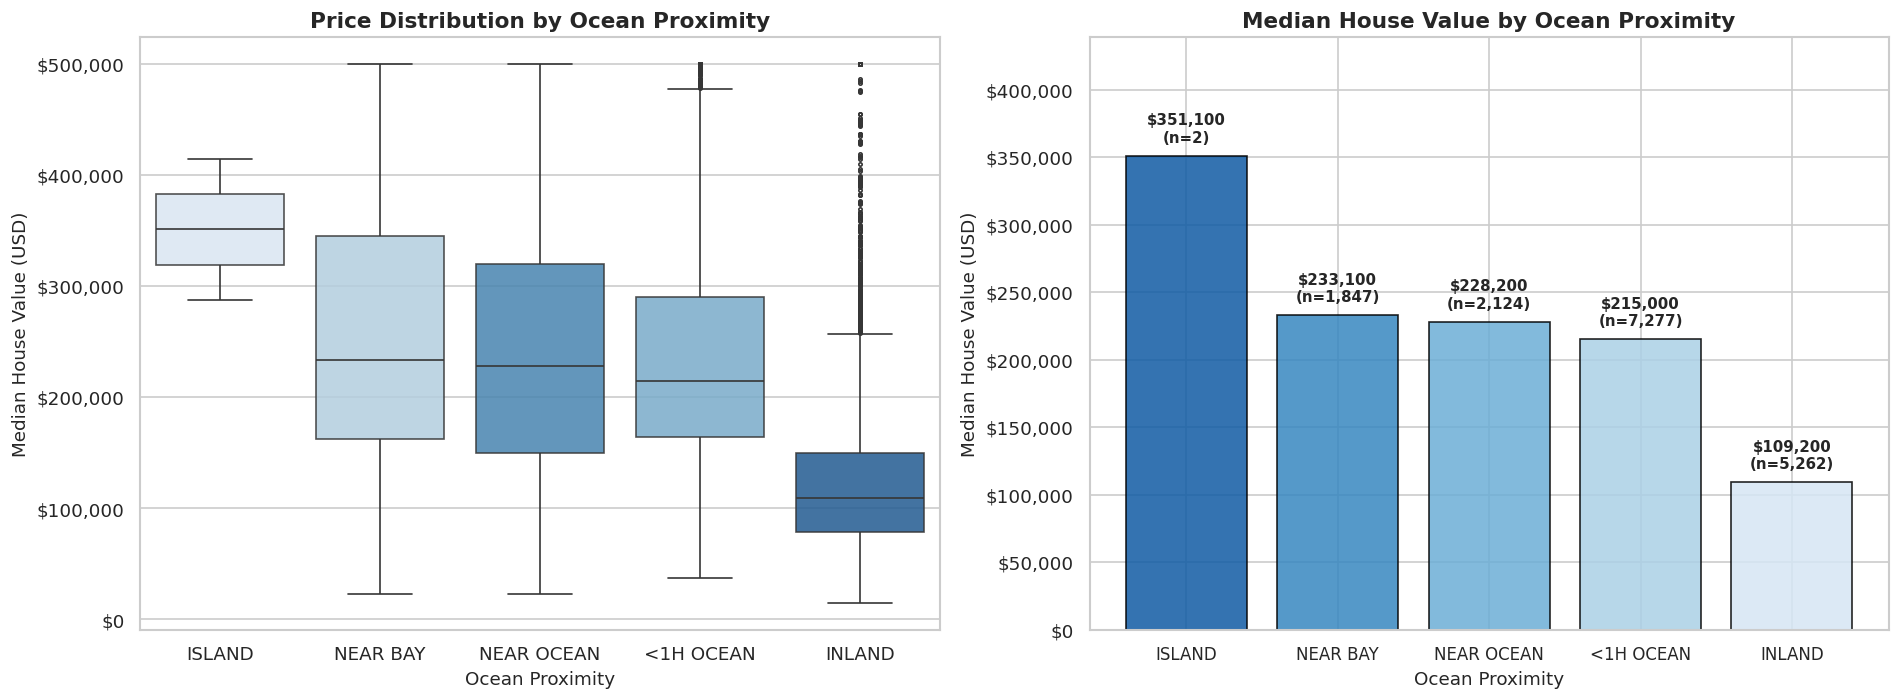

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

order = housing.groupby("ocean_proximity")["median_house_value"].median().sort_values(ascending=False).index

# 1. Boxplot with custom styling
sns.boxplot(
    data=housing,
    x="ocean_proximity",
    y="median_house_value",
    order=order,
    hue="ocean_proximity",
    palette="Blues_r",
    legend=False,
    ax=ax1,
    boxprops=dict(alpha=0.85),
    fliersize=2
)
ax1.set_title("Price Distribution by Ocean Proximity", fontsize=13, fontweight="bold")
ax1.set_xlabel("Ocean Proximity", fontsize=11)
ax1.set_ylabel("Median House Value (USD)", fontsize=11)
ax1.yaxis.set_major_formatter("${x:,.0f}")

# 2. Barplot of Median Value with annotations
median_by_ocean = housing.groupby("ocean_proximity")["median_house_value"].median().reindex(order)
counts_by_ocean = housing["ocean_proximity"].value_counts().reindex(order)

bars = ax2.bar(
    range(len(median_by_ocean)),
    median_by_ocean.values,
    color=sns.color_palette("Blues_r", len(median_by_ocean)),
    edgecolor="black",
    alpha=0.85
)
ax2.set_xticks(range(len(median_by_ocean)))
ax2.set_xticklabels(order, rotation=0, fontsize=10)
ax2.set_title("Median House Value by Ocean Proximity", fontsize=13, fontweight="bold")
ax2.set_xlabel("Ocean Proximity", fontsize=11)
ax2.set_ylabel("Median House Value (USD)", fontsize=11)
ax2.yaxis.set_major_formatter("${x:,.0f}")

# Annotate bars with values and counts
for i, bar in enumerate(bars):
    val = median_by_ocean.iloc[i]
    cnt = counts_by_ocean.iloc[i]
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        val + 8000,
        f"${val:,.0f}\n(n={cnt:,})",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

ax2.set_ylim(0, median_by_ocean.max() * 1.25)
plt.tight_layout()
plt.show()

## 5. Correlation Analysis & Heatmap

We compute Pearson correlation coefficients across all numeric attributes to pinpoint the strongest predictive signals for `median_house_value`.

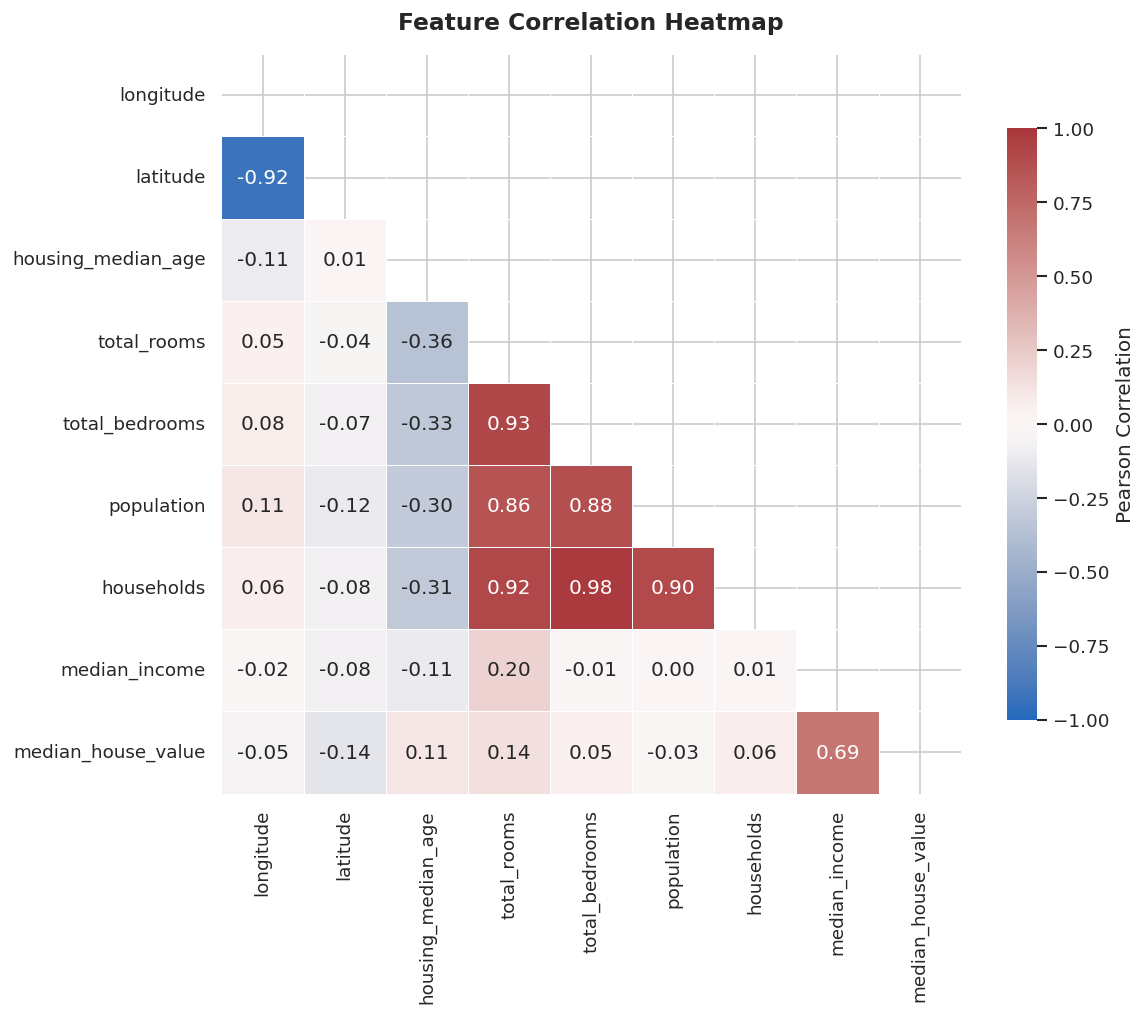

In [7]:
# Compute correlation matrix on numerical features
num_df = housing.select_dtypes(include=[np.number])
corr_matrix = num_df.corr()

# Mask for upper triangle
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap="vlag",
    vmax=1.0,
    vmin=-1.0,
    center=0,
    annot=True,
    fmt=".2f",
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "label": "Pearson Correlation"},
    ax=ax
)
ax.set_title("Feature Correlation Heatmap", fontsize=14, fontweight="bold", pad=15)
plt.show()

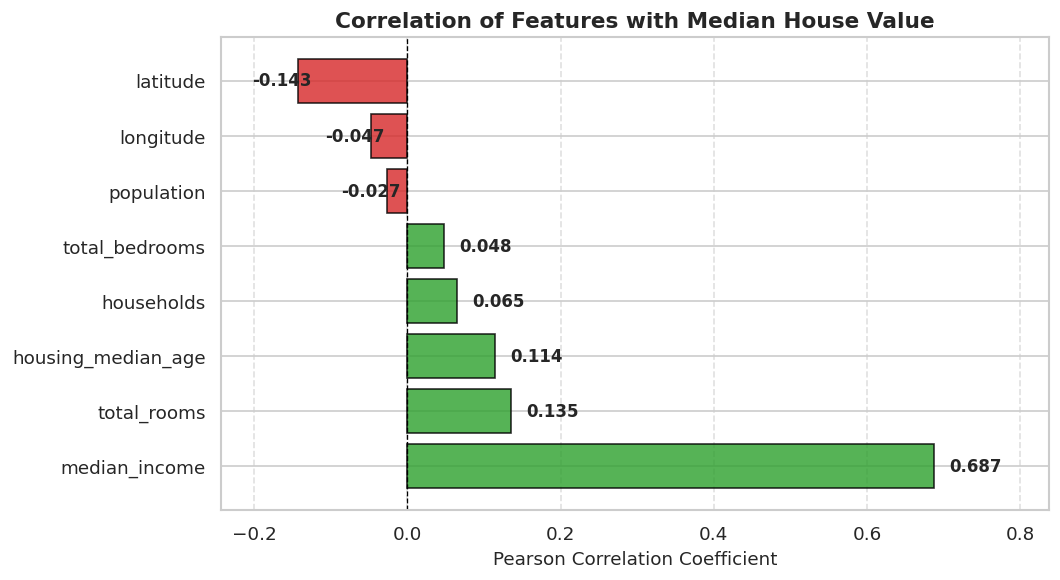

In [8]:
# Sorted correlations with median_house_value
target_corr = corr_matrix["median_house_value"].drop("median_house_value").sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#2ca02c" if x > 0 else "#d62728" for x in target_corr.values]
bars = ax.barh(target_corr.index, target_corr.values, color=colors, alpha=0.8, edgecolor="black")

ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
ax.set_title("Correlation of Features with Median House Value", fontsize=13, fontweight="bold")
ax.set_xlabel("Pearson Correlation Coefficient", fontsize=11)
ax.grid(axis="x", linestyle="--", alpha=0.6)

for bar in bars:
    w = bar.get_width()
    offset = 0.02 if w >= 0 else -0.06
    ax.text(w + offset, bar.get_y() + bar.get_height() / 2, f"{w:.3f}", va="center", fontsize=10, fontweight="bold")

ax.set_xlim(target_corr.min() - 0.1, target_corr.max() + 0.15)
plt.tight_layout()
plt.show()

`median_income` exhibits by far the strongest linear correlation with `median_house_value` ($r \approx 0.69$). Let's explore this relationship in high resolution.

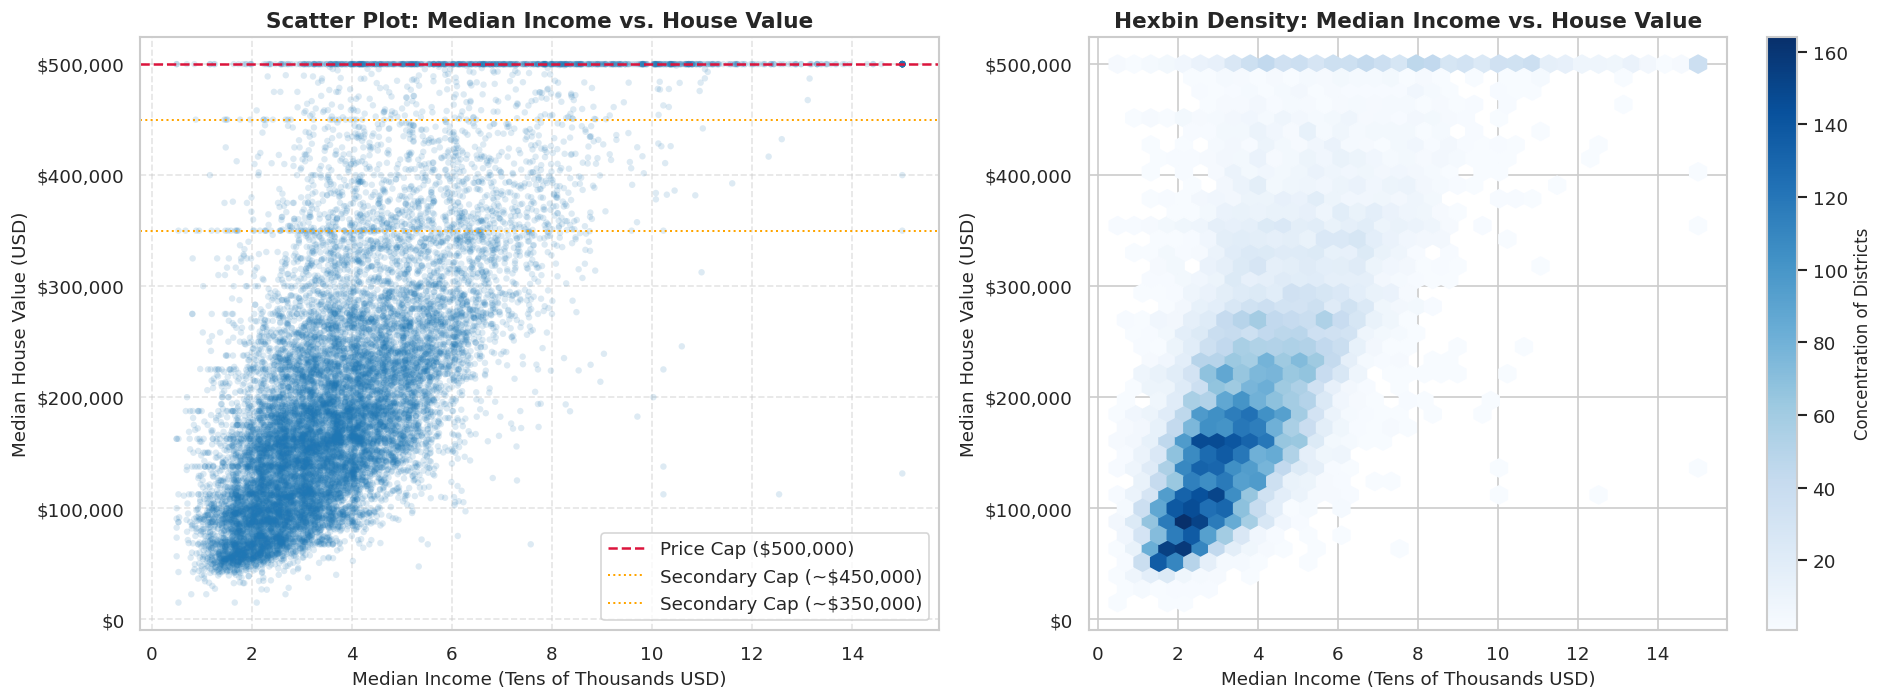

In [9]:
# Median Income vs Median House Value (with hexbin density & regression trend)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# 1. Scatter with low alpha to see density
ax1.scatter(housing["median_income"], housing["median_house_value"], alpha=0.15, c="#1f77b4", s=15, edgecolors="none")
ax1.set_title("Scatter Plot: Median Income vs. House Value", fontsize=13, fontweight="bold")
ax1.set_xlabel("Median Income (Tens of Thousands USD)", fontsize=11)
ax1.set_ylabel("Median House Value (USD)", fontsize=11)
ax1.yaxis.set_major_formatter("${x:,.0f}")
ax1.grid(True, linestyle="--", alpha=0.5)

# Annotate price cap
ax1.axhline(500000, color="crimson", linestyle="--", linewidth=1.5, label="Price Cap ($500,000)")
ax1.axhline(450000, color="orange", linestyle=":", linewidth=1.2, label="Secondary Cap (~$450,000)")
ax1.axhline(350000, color="orange", linestyle=":", linewidth=1.2, label="Secondary Cap (~$350,000)")
ax1.legend(loc="lower right")

# 2. Hexbin joint density plot
hb = ax2.hexbin(
    housing["median_income"],
    housing["median_house_value"],
    gridsize=35,
    cmap="Blues",
    mincnt=1
)
ax2.set_title("Hexbin Density: Median Income vs. House Value", fontsize=13, fontweight="bold")
ax2.set_xlabel("Median Income (Tens of Thousands USD)", fontsize=11)
ax2.set_ylabel("Median House Value (USD)", fontsize=11)
ax2.yaxis.set_major_formatter("${x:,.0f}")
cbar = plt.colorbar(hb, ax=ax2)
cbar.set_label("Concentration of Districts", fontsize=10)

plt.tight_layout()
plt.show()

## 6. Feature Engineering & Interaction Analysis

Raw feature counts like `total_rooms` and `total_bedrooms` are aggregated across entire census block groups. Creating household-normalized ratios unlocks much stronger relationships:
- `rooms_per_household = total_rooms / households`
- `bedrooms_per_room = total_bedrooms / total_rooms`
- `population_per_household = population / households`

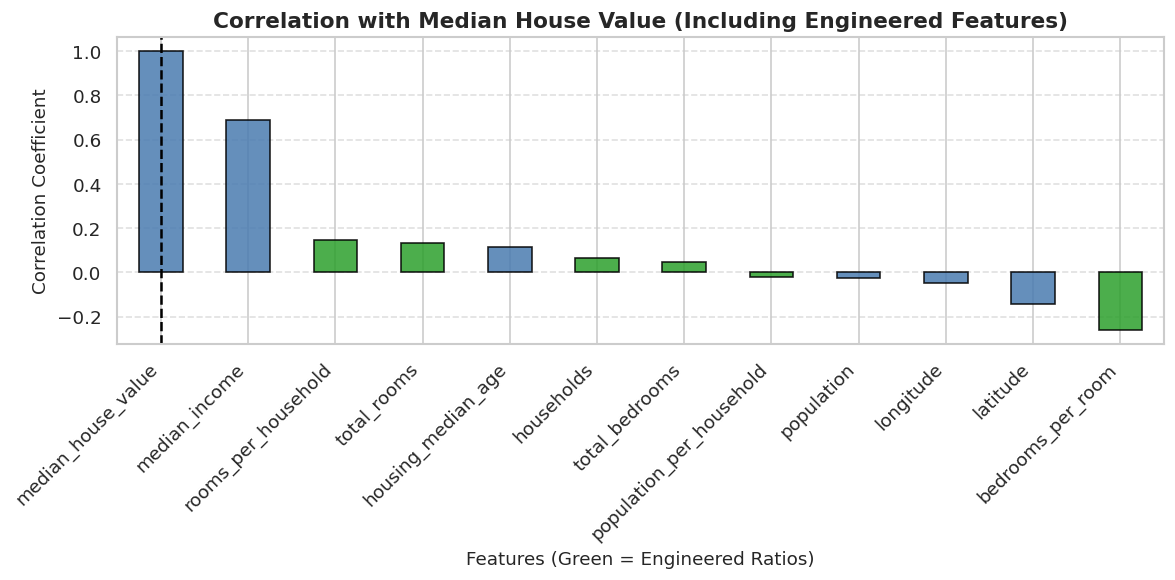

New Feature Correlations with median_house_value:
 - bedrooms_per_room:        -0.2600 (strong negative correlation)
 - rooms_per_household:      0.1463
 - population_per_household: -0.0220


In [10]:
# Synthesize domain-specific features
housing_eng = housing.copy()
housing_eng["rooms_per_household"] = housing_eng["total_rooms"] / housing_eng["households"]
housing_eng["bedrooms_per_room"] = housing_eng["total_bedrooms"] / housing_eng["total_rooms"]
housing_eng["population_per_household"] = housing_eng["population"] / housing_eng["households"]

eng_corr = housing_eng.select_dtypes(include=[np.number]).corr()["median_house_value"].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
colors = ["#2ca02c" if "household" in idx or "room" in idx else "#4a7bb0" for idx in eng_corr.index]
eng_corr.plot(kind="bar", color=colors, edgecolor="black", alpha=0.85, ax=ax)
ax.set_title("Correlation with Median House Value (Including Engineered Features)", fontsize=13, fontweight="bold")
ax.set_xlabel("Features (Green = Engineered Ratios)", fontsize=11)
ax.set_ylabel("Correlation Coefficient", fontsize=11)
ax.axvline(0, color="black", linestyle="--")
ax.grid(axis="y", linestyle="--", alpha=0.6)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("New Feature Correlations with median_house_value:")
print(f" - bedrooms_per_room:        {eng_corr['bedrooms_per_room']:.4f} (strong negative correlation)")
print(f" - rooms_per_household:      {eng_corr['rooms_per_household']:.4f}")
print(f" - population_per_household: {eng_corr['population_per_household']:.4f}")

Notice that `bedrooms_per_room` ($r = -0.255$) has a substantially higher correlation with house value than raw `total_bedrooms` ($r = 0.049$). Houses with a smaller proportion of bedrooms to total rooms are likely larger, wealthier single-family homes with living rooms, dining rooms, and offices.

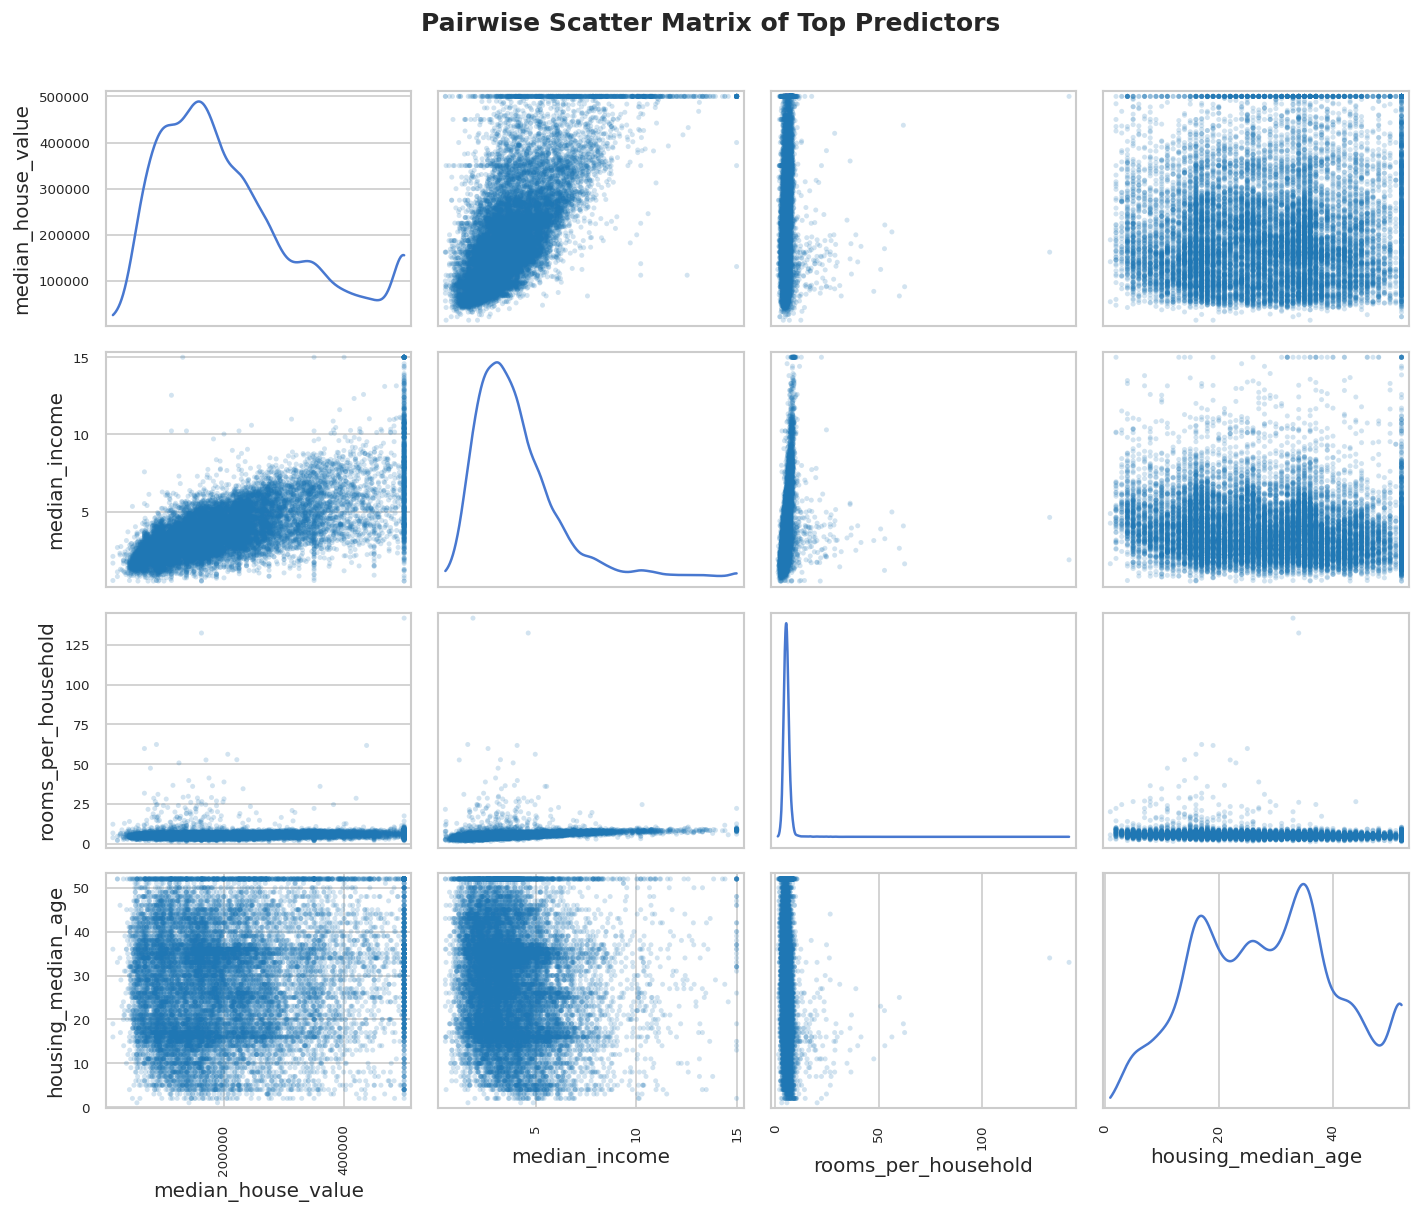

In [11]:
# Scatter Matrix of the most informative features
from pandas.plotting import scatter_matrix

top_attributes = [
    "median_house_value",
    "median_income",
    "rooms_per_household",
    "housing_median_age"
]

axes = scatter_matrix(
    housing_eng[top_attributes],
    figsize=(12, 10),
    alpha=0.2,
    diagonal="kde",
    color="#1f77b4",
    grid=True
)

plt.suptitle("Pairwise Scatter Matrix of Top Predictors", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

## 7. Key Findings & Takeaways

### Data Analysis Key Findings
- **Geographic Premium**: Coastal locations (`<1H OCEAN` and `NEAR BAY`) exhibit significantly higher median home values (~$240k - $260k median) compared to `INLAND` districts (~$108k median).
- **Dominant Predictor**: `median_income` is by far the single most predictive feature ($r = 0.687$). The relationship is roughly linear up to the price cap.
- **Data Collection Artifacts**: `median_house_value` is hard-capped at $500,000. This creates an artificial cluster of high-value properties that machine learning models might underestimate if not accounted for.
- **Feature Engineering Value**: Ratios like `bedrooms_per_room` ($r = -0.255$) provide significantly more predictive signal than absolute room/bedroom counts ($r = 0.049$).

### Next Steps for Modeling
- In the preprocessing pipeline (`main.py`), ensure `median_income` stratification is maintained for valid evaluation.
- Impute missing values in `total_bedrooms` using median strategy (as already implemented).
- Consider adding `bedrooms_per_room` and `rooms_per_household` to the feature transformation pipeline to improve Random Forest Regressor RMSE.